# SAM-6D + FoundationPose — Photoneo PhoXi 3D M

Multi-object 6D pose estimation using the **Photoneo PhoXi 3D M** (blue) camera.

**Pipeline:**
1. **Init** — loads SAM + DINOv2 (ISM) and PEM, renders CAD templates, computes reference descriptors for all 3 models
2. **Load** — reads RGBD data and camera intrinsics from a `.praw` file via `phoxi_api` (or falls back to pre-extracted TIF files)
3. **Forward** — detects all 3 object types simultaneously, returning 6DoF poses, masks, and confidence scores
4. **Refine** — FoundationPose refines each detection's pose using iterative RGB-D re-rendering

**Prerequisites:**
- `pip install phoxi-api` (already installed in cnos2)
- PhoXi Control running (`/usr/bin/PhoXiControl` — it runs as a background service even without the GUI open)
- The `.praw` file is attached as a virtual file camera automatically via `phoxi_api.attach_file_camera()`
- If PhoXi Control is unavailable, the fallback loads from pre-extracted TIF files — fill in `FX/FY/CX/CY` from PhoXi Control → Camera → Calibration

**Depth convention:** PhoXi DepthMap is in **millimetres** — `depth_scale = 1.0`.

Templates are cached in `sam6d_templates_*/` and skipped on re-runs.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import torch
import cv2
import trimesh
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

from src.sam6d import SAM6D
from src.foundationpose import FoundationPoseRefiner

/home/joon/.virtualenvs/torch_obj_tracking/lib/python3.12/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
PRAW_PATH     = "/home/joon/Pictures/gears_items_test_neo.praw"
DEPTH_SCALE   = 1.0     # PhoXi DepthMap is already in mm
FILE_CAM_NAME = "neo_scan"  # arbitrary name for the file camera slot

try:
    from phoxi_api import PhoXiControl, PhoXiDevice
    phc = PhoXiControl()
    if not phc.is_phoxicontrol_running():
        raise RuntimeError("PhoXi Control is not running — start /usr/bin/PhoXiControl and re-run")

    # Attach the .praw file as a virtual file camera; returns its device ID
    file_cam_id = phc.attach_file_camera(name=FILE_CAM_NAME, paths=PRAW_PATH)
    print(f"Attached file camera: {file_cam_id!r}")

    try:
        with phc.connect(file_cam_id, timeout_ms=30_000) as device:
            device.logout_on_exit = True

            # File cameras need SOFTWARE trigger — freerun never produces frames from a .praw
            device.set_trigger_mode(PhoXiDevice.TriggerMode.SOFTWARE)
            device.start_acquisition()

            # Trigger the playback frame and wait for grabbing to finish
            frame_id = device.trigger_frame(wait_grabbing_end=True)
            frame = device.get_frame(frame_id=frame_id, timeout_ms=60_000)

            # Camera intrinsics — frame.Info is a plain dict; CameraMatrix is a 9-element
            # row-major list of float64 decoded from the .praw calibration block
            # Uncomment to inspect all available keys:
            # import pprint; pprint.pprint(frame.Info)
            cam_mat = frame.Info.get("CameraMatrix") or frame.Info.get("IntensityCameraMatrix")
            if cam_mat is None:
                raise KeyError(f"CameraMatrix not in frame.Info — keys: {list(frame.Info.keys())}")
            K = np.array(cam_mat, dtype=np.float32).reshape(3, 3)

            # phoxi_api returns (H, W, 1) arrays — squeeze to (H, W) for SAM-6D
            depth_raw = np.array(frame.DepthMap, dtype=np.float32).squeeze()
            texture   = np.array(frame.Texture).squeeze()

    finally:
        phc.detach_file_camera(file_cam_id)

    print("[phoxi_api] Loaded from .praw file camera.")

except Exception as e:
    print(f"[fallback] {e!r}")
    import tifffile
    PREFIX    = "/home/joon/Pictures/gears_items_test_neo_raw_IMG_"
    depth_raw = tifffile.imread(PREFIX + "DepthMap.tif").astype(np.float32)
    texture   = np.array(Image.open(PREFIX + "Texture_8Bit.png"))

    # Fill from PhoXi Control → Camera → Calibration → Camera Matrix
    FX, FY, CX, CY = None, None, None, None   # <── FILL IN
    K = np.array([[FX, 0, CX], [0, FY, CY], [0, 0, 1]], dtype=np.float32)
    print("[fallback] Loaded TIF files. Fill in FX/FY/CX/CY from PhoXi Control \u2192 Camera \u2192 Calibration.")

# Normalize texture \u2192 8-bit RGB (PhoXi texture is 16-bit grayscale)
if texture.dtype != np.uint8:
    t_max   = float(texture.max())
    texture = ((texture / t_max) * 255).clip(0, 255).astype(np.uint8) if t_max > 0 else np.zeros_like(texture, dtype=np.uint8)
rgb   = np.stack([texture, texture, texture], axis=-1) if texture.ndim == 2 else texture
depth = depth_raw

print(f"K:\n{K}")
print(f"RGB:   {rgb.shape}")
print(f"Depth: {depth.shape}  range {depth.min():.0f}\u2013{depth.max():.0f} mm")

[fallback] PhoXiError('PhoXi API library not found')


FileNotFoundError: [Errno 2] No such file or directory: '/home/joon/Pictures/gears_items_test_neo_raw_IMG_DepthMap.tif'

In [ ]:
# Set to (height, width) to center-crop before inference; None = use full image
CROP_SIZE = (1024+128, 1024+512)

if CROP_SIZE is not None:
    crop_h, crop_w = CROP_SIZE
    H, W = rgb.shape[:2]
    if crop_h > H or crop_w > W:
        raise ValueError(f"CROP_SIZE {CROP_SIZE} exceeds image size ({H}, {W})")

    y0 = (H - crop_h) // 2
    x0 = (W - crop_w) // 2

    rgb   = rgb  [y0:y0+crop_h, x0:x0+crop_w]
    depth = depth[y0:y0+crop_h, x0:x0+crop_w]

    # Shift principal point — focal lengths are unchanged by a crop
    K = K.copy()
    K[0, 2] -= x0   # CX
    K[1, 2] -= y0   # CY

    print(f"Center-cropped: {H}x{W} \u2192 {crop_h}x{crop_w}  (offset x0={x0}, y0={y0})")
    print(f"Updated K:\n{K}")
else:
    print(f"No crop — using full {rgb.shape[:2]} image")

Center-cropped: 2192x2928 → 1152x1536  (offset x0=696, y0=520)
Updated K:
[[2.8242166e+03 0.0000000e+00 5.6117993e+02]
 [0.0000000e+00 2.8239719e+03 4.8944037e+02]
 [0.0000000e+00 0.0000000e+00 1.0000000e+00]]


In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

CAD_PATHS = [
    "/home/joon/Downloads/cad_files/gear/helical_gear.stl",
    "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-Flipper_v7motor_adapter.stl",
    "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-gear_bigger_dummy.stl",
]
MODEL_IDS = ["helical_gear", "carrier_flipper", "carrier_gear"]
TEMPLATE_DIRS = [
    "./sam6d_templates_helical_gear",
    "./sam6d_templates_carrier_flipper",
    "./sam6d_templates_carrier_gear",
]
MESH_COLORS = [
    ( 58,  55,  52),   # helical_gear    — dark warm gray  (~22% luminance)
    ( 12,  52, 160),   # carrier_flipper — dark cobalt blue (~20% luminance)
    ( 12,  52, 160),   # carrier_gear    — same filament as carrier_flipper
]
FLAT_SHADING = True
CAD_PATHS_BY_ID = dict(zip(MODEL_IDS, CAD_PATHS))

Using device: cuda


In [4]:
model = SAM6D(
    cad_path=CAD_PATHS,
    model_ids=MODEL_IDS,
    template_dirs=TEMPLATE_DIRS,
    device=DEVICE,

    sam_model_type="vit_h",
    stability_score_thresh=0.94,

    reset_templates=False,
    mesh_color=MESH_COLORS,
    flat_shading=FLAT_SHADING,
    roughness=0.8,
    metallic=0.0,
    light_energy=350,

    det_score_thresh=0.4,
    confidence_thresh=0.4,
    visible_thred=0.15,
    n_template_view=42,
    min_component_area_ratio=0.005,
    mask_overlap_thresh=0.2,
    pose_score_thresh=0.5,

    half_precision=True,
)

load pre-trained checkpoint from: /home/joon/Projects/cnos/checkpoints/mae_pretrain_vit_base.pth
Using blender in /home/joon/blender/blender-4.2.1-linux-x64
Using temporary directory: /dev/shm/blender_proc_4e08d7935163464485c11e838ccd9663
Blender 4.2.1 LTS (hash 396f546c9d82 built 2024-08-19 23:32:23)
Selecting render devices...
Device NVIDIA RTX A6000 of type OPTIX found and used.
Device AMD Ryzen 7 5800X 8-Core Processor of type CPU found and used.
Timer 'STL Import' took 15.36 ms
Rendering 1 frames of colors...
Total         ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ -:--:--  
Total         ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ -:--:--  
Total         ━ … Rendering frame 1 of 1                                        
Total         ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ -:--:-- Rendering frame 1 of 1
Total         ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ -:--:-- Rendering frame 1 of 1     
Total         ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ -:--:-- Rendering frame 1 of 1     
Total         ━━━━━━━━━━━━

In [ ]:
results = model(rgb, depth, K, depth_scale=DEPTH_SCALE)

N = len(results["poses"])
print(f"Detections: {N}")
for i in range(N):
    print(
        f"[{i}]  model_id={results['model_ids'][i]!r:22s}"
        f"  ism={results['ism_scores'][i]:.3f}"
        f"  pose_score={results['pose_scores'][i]:.3f}"
    )

Detections: 6
[0]  model_id='carrier_gear'          ism=0.754  pose_score=0.754
[1]  model_id='helical_gear'          ism=0.680  pose_score=0.680
[2]  model_id='carrier_flipper'       ism=0.779  pose_score=0.776
[3]  model_id='carrier_flipper'       ism=0.559  pose_score=0.553
[4]  model_id='carrier_gear'          ism=0.709  pose_score=0.698
[5]  model_id='carrier_gear'          ism=0.779  pose_score=0.779


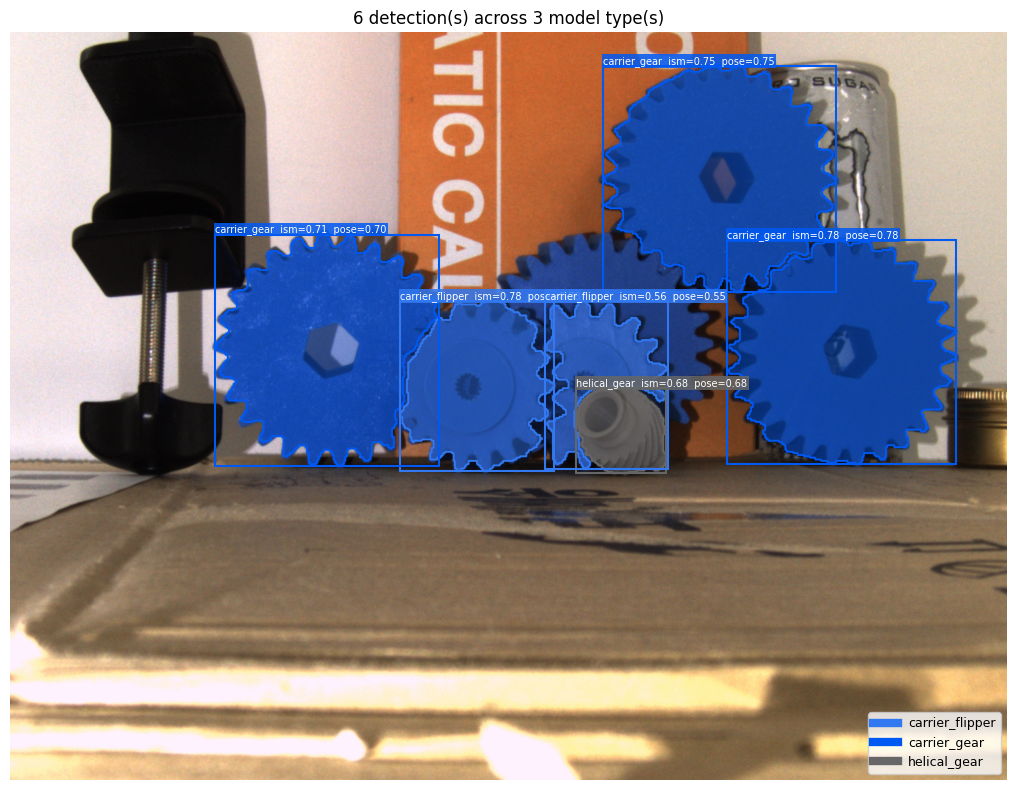

In [ ]:
def visualize_multi_model_detections(rgb, results, alpha=0.4):
    MODEL_PALETTE = {
        "helical_gear":    np.array([102, 102, 102]),
        "carrier_flipper": np.array([ 50, 120, 240]),
        "carrier_gear":    np.array([  0,  89, 242]),
    }
    FALLBACK_COLORS = [
        np.array([220,  50,  50]),
        np.array([ 50, 200,  80]),
        np.array([180,  50, 220]),
        np.array([ 50, 220, 220]),
    ]

    masks       = results["masks"]
    boxes       = results["boxes"]
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]
    model_ids   = results.get("model_ids", ["unknown"] * len(masks))

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    unique_models = sorted(set(model_ids))
    color_map = {}
    fallback_idx = 0
    for mid in unique_models:
        if mid in MODEL_PALETTE:
            color_map[mid] = MODEL_PALETTE[mid]
        else:
            color_map[mid] = FALLBACK_COLORS[fallback_idx % len(FALLBACK_COLORS)]
            fallback_idx += 1

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        color = color_map[model_ids[i]]
        overlay[masks[i].astype(bool)] = (
            (1 - alpha) * overlay[masks[i].astype(bool)] + alpha * color
        )

    canvas = overlay.astype(np.uint8)
    for i in order:
        color = color_map[model_ids[i]]
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, color.tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s, mid) in enumerate(
        zip(boxes, ism_scores, pose_scores, model_ids)
    ):
        x1, y1, x2, y2 = box
        color = color_map[mid] / 255.0
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 4,
            f"{mid}  ism={ism_s:.2f}  pose={pose_s:.2f}",
            color="white", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.85, pad=1, edgecolor="none"),
        )

    for mid, color in color_map.items():
        ax.plot([], [], color=color / 255.0, linewidth=6, label=mid)
    ax.legend(loc="lower right", fontsize=9, framealpha=0.8)

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s) across {len(unique_models)} model type(s)")
    plt.tight_layout()
    plt.show()


visualize_multi_model_detections(rgb, results)

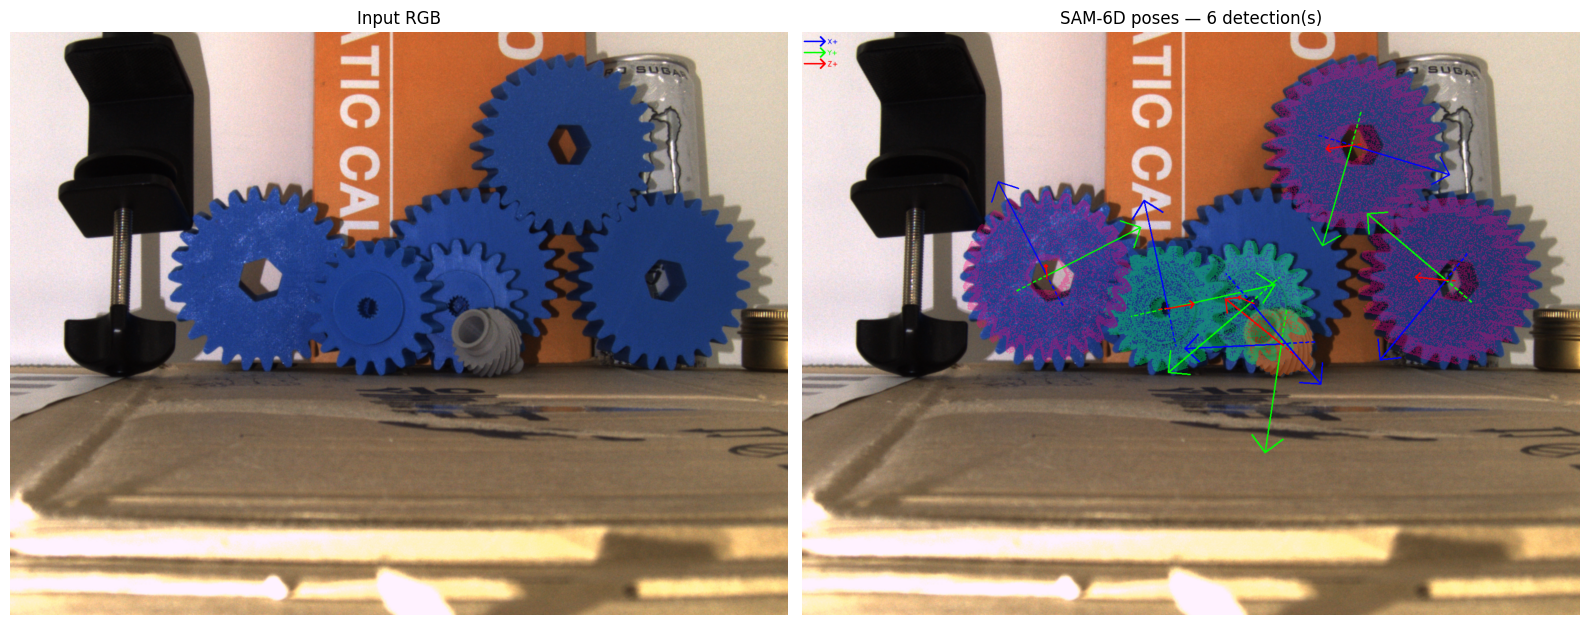

In [ ]:
def project_all_poses(rgb, results, K, cad_paths_by_id, n_pts=4096, axis_len_mm=30):
    """Overlay SAM-6D intermediate poses (before FoundationPose refinement)."""
    poses     = results["poses"]
    model_ids = results.get("model_ids", ["unknown"] * len(poses))

    if not poses:
        print("No detections.")
        return

    MODEL_COLORS = {
        "helical_gear":    (  255, 90, 0),
        "carrier_flipper": (  0, 255, 90),
        "carrier_gear":    (  255,  0, 120),
    }

    mesh_cache = {}
    for mid, cpath in cad_paths_by_id.items():
        mesh = trimesh.load_mesh(cpath)
        mesh_cache[mid] = (mesh.sample(n_pts).astype(np.float32), mesh.centroid.astype(np.float32))

    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    H, W = rgb.shape[:2]

    def pt2img(p_obj, R, t_mm):
        p_cam = R @ p_obj + t_mm
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx), int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx**2 + dy**2) ** 0.5))
        for k in range(0, dist, gap * 2):
            t0, t1 = k / dist, min((k + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas  = rgb.copy()
    overlay = canvas.copy()

    for pose, mid in zip(poses, model_ids):
        R, t = pose["R"], pose["t"]
        pts_mm, _ = mesh_cache.get(mid, next(iter(mesh_cache.values())))
        pts_cam   = (R @ pts_mm.T).T + t[None, :]
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        dot_color = MODEL_COLORS.get(mid, (80, 220, 80))
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 1, dot_color, -1)

    canvas = cv2.addWeighted(canvas, 0.65, overlay, 0.35, 0)

    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]  # X=blue, Y=green, Z=red
    NEG_LEN     = 0.35

    for pose, mid in zip(poses, model_ids):
        R, t = pose["R"], pose["t"]
        _, origin = mesh_cache.get(mid, next(iter(mesh_cache.values())))
        o_img = pt2img(origin, R, t)
        if o_img is None:
            continue
        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3); unit[axis_idx] = 1.0
            tip = pt2img(origin + unit * axis_len_mm, R, t)
            if tip:
                cv2.arrowedLine(canvas, o_img, tip, color, 2, tipLength=0.2)
            neg_tip = pt2img(origin - unit * axis_len_mm * NEG_LEN, R, t)
            if neg_tip:
                draw_dashed_line(canvas, o_img, neg_tip, color, 2)

    for i, (lbl, color) in enumerate([("X+", (0, 0, 255)), ("Y+", (0, 255, 0)), ("Z+", (255, 0, 0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)
        cv2.putText(canvas, lbl, (50, y + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(f"SAM-6D poses — {len(poses)} detection(s)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


project_all_poses(rgb, results, K, CAD_PATHS_BY_ID, n_pts=16000, axis_len_mm=50)

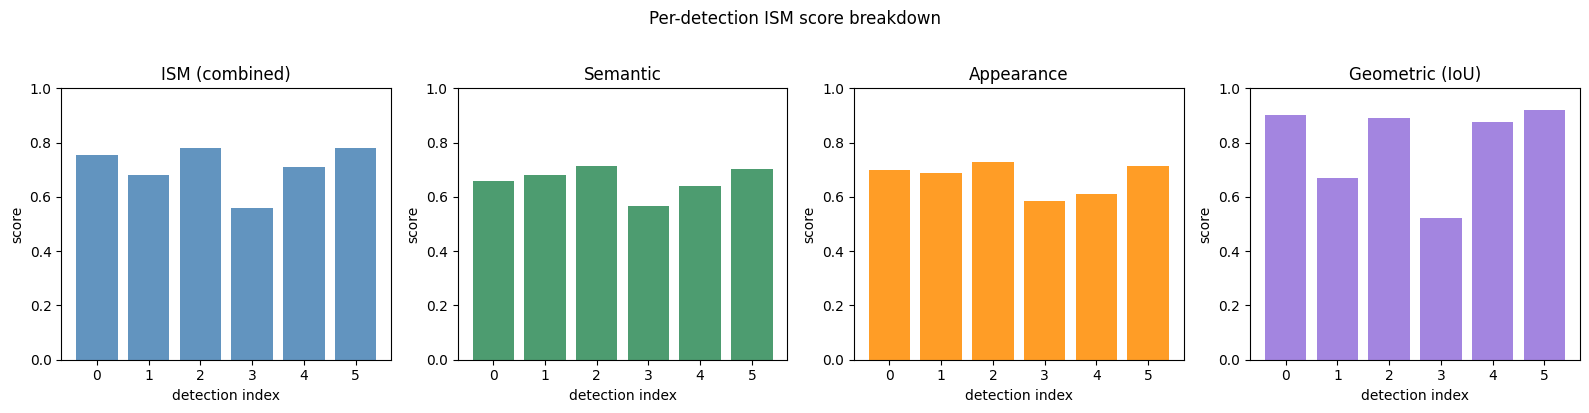

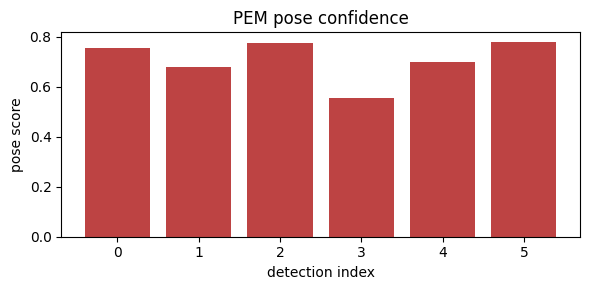

In [ ]:
if len(results["ism_scores"]) > 0:
    N = len(results["ism_scores"])
    det_ids = np.arange(N)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)

    score_data = [
        ("ISM (combined)",  results["ism_scores"],       "steelblue"),
        ("Semantic",        results["semantic_scores"],  "seagreen"),
        ("Appearance",      results["appe_scores"],      "darkorange"),
        ("Geometric (IoU)", results["geometric_scores"], "mediumpurple"),
    ]

    for ax, (title, vals, color) in zip(axes, score_data):
        ax.bar(det_ids, vals, color=color, alpha=0.85)
        ax.set_title(title)
        ax.set_xlabel("detection index")
        ax.set_ylabel("score")
        ax.set_xticks(det_ids)
        ax.set_ylim(0, 1)

    plt.suptitle("Per-detection ISM score breakdown", y=1.02)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(max(6, N * 0.8), 3))
    ax.bar(det_ids, results["pose_scores"], color="firebrick", alpha=0.85)
    ax.set_title("PEM pose confidence")
    ax.set_xlabel("detection index")
    ax.set_ylabel("pose score")
    ax.set_xticks(det_ids)
    plt.tight_layout()
    plt.show()
else:
    print("No detections to display.")

In [ ]:
# Free SAM6D VRAM (~5 GB) before FoundationPose
model.offload_to_cpu()
torch.cuda.empty_cache()   # return fragmented buffers to the allocator

fp = FoundationPoseRefiner(
    cad_path=CAD_PATHS,
    model_ids=MODEL_IDS,
    device=DEVICE,
    mesh_scale=1/1000.0,
    est_refine_iter=5,
    track_refine_iter=2,
    min_pose_score=0.0,
    debug=0,
    half_precision=True,   # fp16 RefineNet + ScoreNet: ~50% less VRAM
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


[__init__()] welcome
[__init__()] self.cfg: 
 lr: 0.0001
c_in: 6
zfar: .inf
debug: null
w_rot: 0.1
n_view: 1
run_id: null
use_BN: true
rot_rep: axis_angle
ckpt_dir: /home/joon/Projects/cnos/FoundationPose-main/learning/training/../../weights/2023-10-28-18-33-37/model_best.pth
exp_name: 2023-10-28-18-33-37
save_dir: /tmp/2023-10-28-18-33-37/
loss_type: l2
optimizer: adam
trans_rep: tracknet
batch_size: 64
crop_ratio: 1.2
use_normal: false
BN_momentum: 0.1
max_num_key: null
warmup_step: -1
input_resize:
- 160
- 160
max_step_val: 1000
normal_uint8: false
vis_interval: 1000
weight_decay: 0
n_max_objects: null
normalize_xyz: true
clip_grad_norm: 'Infinity'
rot_normalizer: 0.3490658503988659
trans_normalizer:
- 0.019999999552965164
- 0.019999999552965164
- 0.05000000074505806
max_step_per_epoch: 25000
val_epoch_interval: 10
n_dataloader_workers: 60
enable_amp: true
use_mask: false

[__init__()] self.h5_file:
[__init__()] Using pretrained model from /home/joon/Projects/cnos/FoundationPose-mai

Warp 1.13.0 initialized:
   CUDA Toolkit 12.9, Driver 13.2
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA RTX A6000" (47 GiB, sm_86, mempool enabled)
   Kernel cache:
     /home/joon/.cache/warp/1.13.0


[__init__()] Using pretrained model from /home/joon/Projects/cnos/FoundationPose-main/learning/training/../../weights/2024-01-11-20-02-45/model_best.pth
[__init__()] init done
[_load_models()] FoundationPose models loaded.


In [ ]:
refined = fp(rgb, depth, K, results, depth_scale=DEPTH_SCALE)

print(f"Refined {len(refined)} detection(s)\n")
for r in refined:
    print(
        f"  model_id={r['model_id']!r:22s}"
        f"  fp_score={r['fp_score']:.4f}"
        f"  t={r['pose'][:3, 3]}"
    )

[_load_models()] FoundationPose models loaded.
[reset_object()] self.diameter:0.0839491756569033, vox_size:0.004197458782845165
[reset_object()] self.pts:torch.Size([438, 3])
[reset_object()] reset done
[make_rotation_grid()] cam_in_obs:(42, 4, 4)
[make_rotation_grid()] rot_grid:(252, 4, 4)
[make_rotation_grid()] after cluster, rot_grid:(252, 4, 4)
[make_rotation_grid()] self.rot_grid: torch.Size([252, 4, 4])
[register()] Welcome
[register()] poses:(252, 4, 4)
[register()] after viewpoint, add_errs min:-1.0
/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)
[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.01999

num original candidates = 252
num of pose after clustering: 252
Module Utils 9293bed load on device 'cuda:0' took 0.52 ms  (cached)


[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make

num original candidates = 252
num of pose after clustering: 252


[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop

num original candidates = 252
num of pose after clustering: 252


... (4 outputs left out)

[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] f

num original candidates = 252
num of pose after clustering: 252


[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop

Refined 6 detection(s)

  model_id='carrier_gear'          fp_score=49.5000  t=[0.17436673 0.00130845 0.7046201 ]
  model_id='carrier_flipper'       fp_score=78.6562  t=[0.03405198 0.01327019 0.639982  ]
  model_id='carrier_gear'          fp_score=51.7188  t=[ 0.129899   -0.06295868  0.66915464]
  model_id='carrier_gear'          fp_score=95.4062  t=[-1.6400184e-02  4.2228145e-04  6.6461241e-01]
  model_id='helical_gear'          fp_score=90.2188  t=[0.08794647 0.02998695 0.63212496]
  model_id='carrier_flipper'       fp_score=73.1719  t=[0.07629792 0.01126348 0.6548186 ]


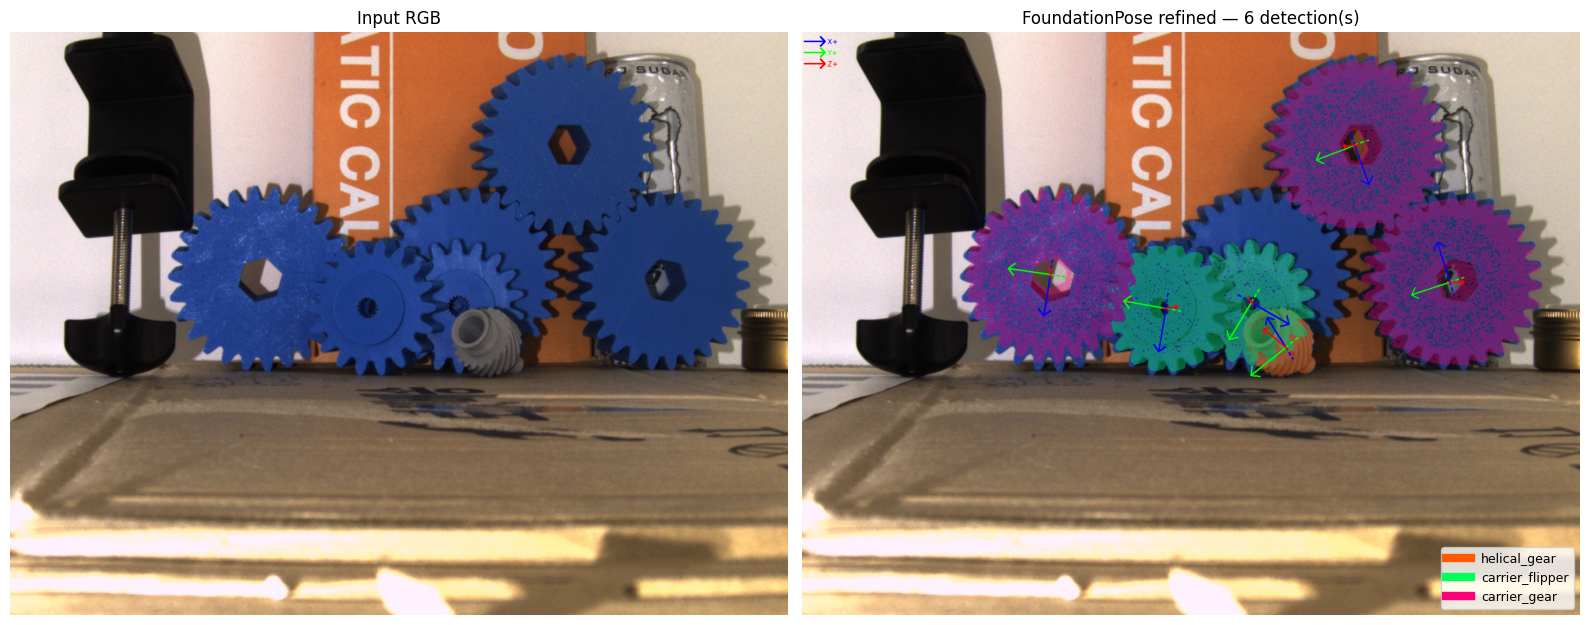

In [ ]:
def project_fp_poses_multi(rgb, refined_results, K, cad_paths_by_id, mesh_scale=1/1000.0,
                            n_pts=4096, axis_len_m=0.02):
    """Project FoundationPose refined poses for multiple model types."""
    MODEL_COLORS = {
        "helical_gear":    (  255, 90, 0),
        "carrier_flipper": (  0, 255, 90),
        "carrier_gear":    (  255,  0, 120),
    }
    FALLBACK = (80, 220, 80)

    if not refined_results:
        print("No refined poses to display.")
        return

    pts_cache    = {}
    origin_cache = {}
    for mid, cpath in cad_paths_by_id.items():
        mesh = trimesh.load_mesh(cpath)
        pts_cache[mid]    = mesh.sample(n_pts).astype(np.float64) * mesh_scale
        origin_cache[mid] = ((mesh.bounds[0] + mesh.bounds[1]) / 2).astype(np.float64) * mesh_scale

    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    H, W = rgb.shape[:2]

    def project_pt(p_obj_m, pose):
        p_cam = pose[:3, :3] @ p_obj_m + pose[:3, 3]
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx), int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx**2 + dy**2) ** 0.5))
        for k in range(0, dist, gap * 2):
            t0, t1 = k / dist, min((k + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas  = rgb.copy()
    overlay = canvas.copy()

    for r in refined_results:
        mid       = r.get("model_id", "unknown")
        pose      = r["pose"].astype(np.float64)
        pts_m     = pts_cache.get(mid, next(iter(pts_cache.values())))
        dot_color = MODEL_COLORS.get(mid, FALLBACK)

        pts_cam = (pose[:3, :3] @ pts_m.T).T + pose[:3, 3]
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 2, dot_color, -1)

    canvas = cv2.addWeighted(canvas, 0.65, overlay, 0.35, 0)

    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]  # X=blue, Y=green, Z=red
    NEG_RATIO   = 0.35

    for r in refined_results:
        mid    = r.get("model_id", "unknown")
        pose   = r["pose"].astype(np.float64)
        origin = origin_cache.get(mid, next(iter(origin_cache.values())))
        o_img  = project_pt(origin, pose)
        if o_img is None:
            continue
        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3); unit[axis_idx] = 1.0
            tip = project_pt(origin + unit * axis_len_m, pose)
            if tip:
                cv2.arrowedLine(canvas, o_img, tip, color, 2, tipLength=0.2)
            neg = project_pt(origin - unit * axis_len_m * NEG_RATIO, pose)
            if neg:
                draw_dashed_line(canvas, o_img, neg, color, 2)

    for i, (lbl, color) in enumerate([("X+", (0, 0, 255)), ("Y+", (0, 255, 0)), ("Z+", (255, 0, 0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)
        cv2.putText(canvas, lbl, (50, y + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(f"FoundationPose refined — {len(refined_results)} detection(s)")
    axes[1].axis("off")

    for mid, color in MODEL_COLORS.items():
        if mid in cad_paths_by_id:
            axes[1].plot([], [], color=np.array(color) / 255.0, linewidth=6, label=mid)
    axes[1].legend(loc="lower right", fontsize=9, framealpha=0.8)

    plt.tight_layout()
    plt.show()


project_fp_poses_multi(rgb, refined, K, CAD_PATHS_BY_ID, n_pts=16000, axis_len_m=0.02)